# Ejercicio 1 — Filtro de Kalman sobre datos de movimiento (x, y)

**Fase 3 – Filtrado de series temporales y transformaciones en el dominio de la frecuencia**

## Objetivo
Es aplicar un **filtro de Kalman (KF)** a un conjunto de mediciones ruidosas de una trayectoria en el plano
(`xy_motion_kalman_filter_example.csv`) para obtener una estimación suavizada de la posición, siguiendo
los pasos clásicos del algoritmo:

1. Estimación inicial del **vector de estado** y de la **matriz de covarianza**.
2. **Predicción** del estado y de la covarianza para el siguiente paso de tiempo.
3. Cálculo de la **ganancia de Kalman**.
4. **Actualización** de las estimaciones con la medición.
5. Repetir el análisis con una varianza del modelo **mayor** que la varianza de medición y analizar la **convergencia**.

## ¿Qué es el filtro de Kalman?
| Paso | Ecuaciones | En palabras |
|---|---|---|
| **1. Predicción** | $\hat{x}^- = F\,\hat{x}$ <br> $P^- = F\,P\,F^T + Q$ | Uso mi modelo para adelantarme un paso. La incertidumbre **crece** (sumo $Q$). |
| **2. Ganancia de Kalman** | $K = P^- H^T\,(H P^- H^T + R)^{-1}$ | Calculo **cuánto creerle a la medición** frente a la predicción. |
| **3. Actualización** | $\hat{x} = \hat{x}^- + K\,(z - H\hat{x}^-)$ <br> $P = (I - K H)\,P^-$ | Corrijo la predicción con la medición $z$. La incertidumbre **baja**. |

### Significado de cada símbolo

| Símbolo | Significado | En nuestro código |
|---|---|---|
| $\hat{x}$ | Vector de **estado** estimado: `[posición, velocidad]` | `x_est` |
| $P$ | **Covarianza** del estado (qué tan inseguro estoy) | `P` |
| $F$ | Matriz del modelo: cómo evoluciona el estado | `F` |
| $H$ | Matriz de medición: qué parte del estado se mide (solo la posición) | `H` |
| $Q$ | Ruido del **modelo** (qué tanto puede "desviarse" la realidad de mi modelo) | `estimated_model_variance` |
| $R$ | Ruido de la **medición** (qué tan malo es el sensor) | `estimated_measurement_variance` |
| $z$ | Medición recibida | `z` |
| $K$ | **Ganancia de Kalman** | `K` |

### La idea clave para entender es: Q contra R

Para un caso simple de un solo número, la ganancia es $K = \dfrac{P^-}{P^- + R}$:

- Si **$R$ es grande** (sensor malo) → $K$ se acerca a **0** → el filtro **confía en el modelo** y suaviza mucho.
- Si **$Q$ es grande** (modelo poco confiable) → $P^-$ es grande → $K$ se acerca a **1** → el filtro **confía en la medición** y casi la copia.

### Modelo que usaremos

El objeto se mueve en el plano. Trataremos **cada coordenada por separado** (x e y) con un modelo de *velocidad casi constante*:

$$\text{estado} = \begin{bmatrix}\text{posición}\\ \text{velocidad}\end{bmatrix},\qquad F=\begin{bmatrix}1 & \Delta t\\ 0 & 1\end{bmatrix},\qquad H=\begin{bmatrix}1 & 0\end{bmatrix}$$

con $\Delta t = 1$ (el tiempo entre mediciones es "un paso"), $Q = \text{estimated\_model\_variance}\cdot I$ y $R = \text{estimated\_measurement\_variance}$.

El filtro balancea ambas fuentes de información mediante la **ganancia de Kalman K**:
cuando la medición es muy ruidosa (R grande) --> K es pequeño y se confía en el modelo;
cuando el modelo es incierto (Q grande) --> K es grande y se confía en la medición.



Tomado de: https://es.wikipedia.org/wiki/Filtro_de_Kalman

## 1. Carga y exploración de los datos

El archivo contiene 205 puntos (columna `x`, columna `y`) que representan posiciones medidas
(con ruido) de un objeto que se mueve en el plano.

In [16]:

# Importamos las librerías y cargamos los datos

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Cargamos el CSV con las posiciones medidas (x, y)
datos = pd.read_csv('C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_3\\phase_3\\data\\Appendix 1 - xy_motion_kalman_filter_example.csv', header=None,
                    names=['x', 'y'])
mediciones = datos.values          # matriz de forma (205, 2)

print('Número de mediciones:', len(mediciones))
print('Primeras 5 filas:')
print(datos.head())

Número de mediciones: 205
Primeras 5 filas:
      x     y
0  2.35  1.45
1  3.55  1.80
2  3.00  2.90
3  2.65  4.20
4  2.95  5.15


In [12]:
datos.info()  # información del DataFrame

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       205 non-null    float64
 1   y       205 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


In [13]:
datos.head()

,x,y
0,2.35,1.45
1,3.55,1.80
2,3.00,2.90
3,2.65,4.20
4,2.95,5.15


In [14]:
datos.describe()  # estadísticas descriptivas del DataFrame

,x,y
count,205.000000,205.000000
mean,29.228293,16.100000
std,13.064487,6.608298
min,2.350000,1.450000
25%,20.200000,10.950000
50%,32.350000,16.750000
75%,39.750000,21.550000
max,47.300000,26.600000


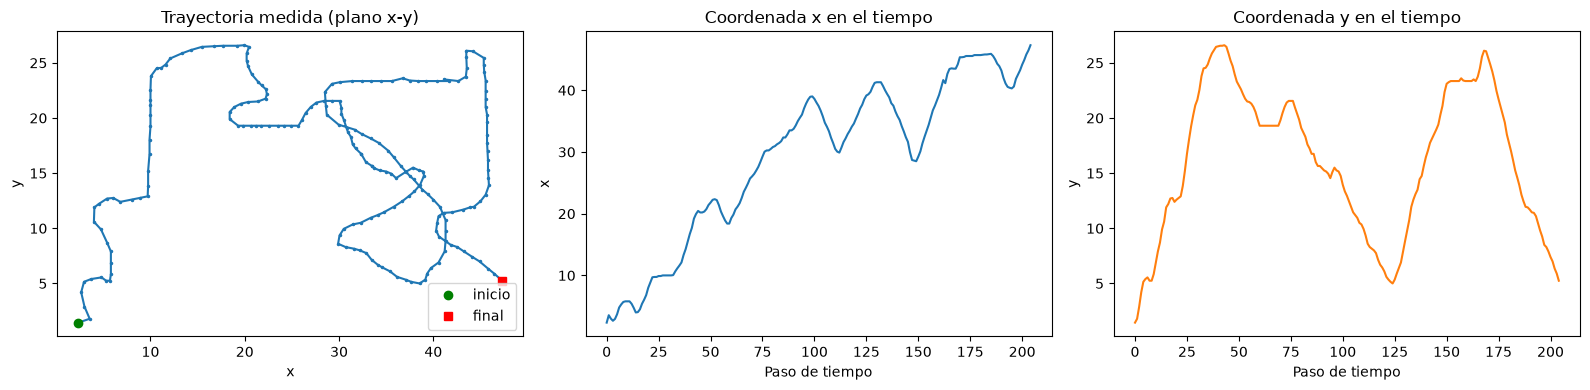

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

# 1) Trayectoria en el plano: y contra x
ejes[0].plot(datos["x"], datos["y"], ".-", markersize=3)
ejes[0].plot(datos["x"][0], datos["y"][0], "go", label="inicio")
ejes[0].plot(datos["x"].iloc[-1], datos["y"].iloc[-1], "rs", label="final")
ejes[0].set_title("Trayectoria medida (plano x-y)")
ejes[0].set_xlabel("x"); ejes[0].set_ylabel("y"); ejes[0].legend()

# 2) x en función del tiempo (el tiempo es el número de medición)
ejes[1].plot(datos["x"], color="tab:blue")
ejes[1].set_title("Coordenada x en el tiempo")
ejes[1].set_xlabel("Paso de tiempo"); ejes[1].set_ylabel("x")

# 3) y en función del tiempo
ejes[2].plot(datos["y"], color="tab:orange")
ejes[2].set_title("Coordenada y en el tiempo")
ejes[2].set_xlabel("Paso de tiempo"); ejes[2].set_ylabel("y")

plt.tight_layout()
plt.show()

Vemos que la trayectoria muestra curvas y cambios de dirección, y se aprecia un
ligera dispersión propia del ruido de medición. El objetivo con el filtro de Kalman es suavizar esta trayectoria
eliminando el ruido sin perder la forma del movimiento.

## 2. Estimación inicial del estado y de la covarianza

### Vector de estado x̂
Usamos un modelo de **velocidad constante** en 2 dimensiones, con Δt = 1 entre muestras:

  x̂ = [x, y, vx, vy]ᵀ   →  posición y velocidad en cada eje.

- La posición inicial se toma de la **primera medición** (lo único que sabemos al inicio).
- La velocidad inicial se supone **0** (no tenemos información previa).

### Matriz de covarianza P
Representa la **incertidumbre** de la estimación inicial. Como no conocemos nada con certeza,
inicializamos P con valores grandes (100·I₄): «podemos estar muy lejos de la verdad».

### Matrices del modelo
- **F** (transición de estado): integra la velocidad en la posición con Δt = 1.
- **H** (observación): solo medimos posición, no velocidad.
- **Q** = var_modelo·I₄ : ruido del modelo (cuánto se desvía el movimiento real del modelo ideal).
- **R** = var_medicion·I₂ : ruido del sensor (cuánto se desvía la medición de la posición real).

In [15]:
# Estimación inicial del estado y de la covarianza

dt = 1.0   # intervalo de tiempo entre mediciones. Es nuestra hipótesis de que las mediciones se hacen a intervalos regulares de 1 segundo.

# Vector de estado inicial: [x, y, vx, vy] nos ayuda a representar la posición y velocidad del objeto en el espacio 2D. 
# Inicialmente, asumimos que la velocidad es desconocida (0).
estado = np.array([mediciones[0, 0],   # x inicial  = primera medición en x
                   mediciones[0, 1],   # y inicial  = primera medición en y
                   0.0,                # vx inicial = 0 (desconocida)
                   0.0])               # vy inicial = 0 (desconocida)

# Matriz de covarianza inicial: incertidumbre alta
#este número alto (100.0) indica que tenemos poca confianza en nuestra estimación inicial del estado, especialmente en las velocidades.
P = np.eye(4) * 100.0

print('Vector de estado inicial x̂:')
print(estado)
print('\nMatriz de covarianza inicial P:')
print(P)

Vector de estado inicial x̂:
[2.35 1.45 0.   0.  ]

Matriz de covarianza inicial P:
[[100.   0.   0.   0.]
 [  0. 100.   0.   0.]
 [  0.   0. 100.   0.]
 [  0.   0.   0. 100.]]


## 3. Filtro de Kalman completo: predicción → ganancia → actualización

En cada paso de tiempo se ejecutan **dos fases**:

**Fase de predicción (time update):**
- x̂⁻ = F·x̂          (proyectamos el estado al futuro con el modelo)
- P⁻ = F·P·Fᵀ + Q     (la incertidumbre crece por el ruido del modelo)

**Fase de actualización (measurement update):**
- K = P⁻·Hᵀ·(H·P⁻·Hᵀ + R)⁻¹     (ganancia de Kalman: peso entre modelo y medición)
- x̂ = x̂⁻ + K·(z − H·x̂⁻)          (corregimos la predicción con la medición z)
- P = (I − K·H)·P⁻                 (la incertidumbre disminuye al incorporar la medición)



In [19]:
# Implementación del filtro de Kalman 2D (velocidad constante)

def filtro_kalman_2d(mediciones, var_modelo, var_medicion, dt=1.0, detalle=False):
    '''Filtro de Kalman con modelo de velocidad constante.
       Estado: [x, y, vx, vy]. Se observa solo la posición (x, y).'''
    n = len(mediciones)
    #esta función implementa el filtro de Kalman para estimar la posición y velocidad de un 
    # objeto en 2D a partir de mediciones ruidosas de su posición.

    # Matriz de transición de estado (modelo de movimiento)
    F = np.array([[1, 0, dt, 0],
                  [0, 1, 0, dt],
                  [0, 0, 1,  0],
                  [0, 0, 0,  1]], dtype=float)
# esta matriz F describe cómo el estado del sistema evoluciona de un paso de tiempo al siguiente,
# considerando que la posición cambia según la velocidad y el tiempo transcurrido (dt), 
# mientras que la velocidad se mantiene constante.
    # Matriz de observación: medimos posición x e y (no velocidad)
    H = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0]], dtype=float)
#aquí, H indica que solo podemos observar la posición (x, y) del objeto,
# y no tenemos acceso directo a las velocidades (vx, vy).

    # Covarianzas del ruido del modelo (Q) y de la medición (R)
    Q = var_modelo * np.eye(4)
    R = var_medicion * np.eye(2)

    # --- Estimación inicial (punto 1 del ejercicio) ---
    x = np.array([mediciones[0, 0], mediciones[0, 1], 0.0, 0.0])
    P = np.eye(4) * 100.0

    estados, ganancias, trazas = [], [], []
    for i, z in enumerate(mediciones):
        # paso 1: predicción
        x = F @ x                 # predecir el estado
        P = F @ P @ F.T + Q       # predecir la covarianza

        # paso 2: actualización
        K = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)

        # paso 3: corrección con la medición
        x = x + K @ (z - H @ x)   # corregir con la medición z
        P = (np.eye(4) - K @ H) @ P

        estados.append(x.copy())  # guardar estado estimado [x, y, vx, vy]
        ganancias.append(K[0, 0]) # guardar ganancia (componente x)
        trazas.append(np.trace(P))# guardar incertidumbre total

        # Mostrar los dos primeros pasos para verificar el procedimiento
        if detalle and i < 2:
            print(f'--- Paso t={i} ---')
            print('  Medición z          :', z)
            print('  Estado tras predicción :', np.round(F @ estados[-1], 3) if i>0 else 'inicial')
            print('  Ganancia K[0,0]     :', round(K[0, 0], 4))
            print('  Estado tras actualizar:', np.round(x, 3))

    return np.array(estados), np.array(ganancias), np.array(trazas)


# Función auxiliar: error cuadrático medio (RMSE)
def rmse(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

## 4. Caso 1 — varianza del modelo **menor** que la varianza de medición

Configuración inicial del ejercicio:

- `var_medicion = 1.0` → creemos que el sensor ruida bastante.
- `var_modelo = 0.01` → creemos que el modelo de movimiento describe bien la realidad.

Como **Q < R**, se espera que la ganancia de Kalman sea **pequeña**: el filtro *suaviza* las
mediciones siguiendo sobre todo el modelo.

In [ ]:
# Caso 1: var_modelo (0.01) < var_medicion (1.0)
# ---------------------------------------------------------------
var_modelo_1, var_medicion_1 = 0.01, 1.0

estados_1, ganancias_1, trazas_1 = filtro_kalman_2d(
    mediciones, var_modelo_1, var_medicion_1, detalle=True)
#usamos la función filtro_kalman_2d para estimar la posición y velocidad del objeto a partir de las mediciones ruidosas,
# utilizando una varianza de modelo baja (0.01) y una varianza de medición más alta (1.0), lo que indica que confiamos más en nuestro modelo que en
# las mediciones ruidosas. Así podemos observar cómo el filtro de Kalman ajusta sus estimaciones a lo 
# largo del tiempo, mejorando la precisión de las posiciones estimadas en comparación con las mediciones originales.

pos_kf_1 = estados_1[:, :2]   # posiciones estimadas (x, y)

print('\nCaso 1 -> var_modelo =', var_modelo_1, '| var_medicion =', var_medicion_1)
print('RMSE entre KF y mediciones:', round(rmse(pos_kf_1, mediciones), 3))
print('Ganancia K al inicio y al final:', round(ganancias_1[0], 3), '->', round(ganancias_1[-1], 3))
print('Traza de P al inicio y al final:', round(trazas_1[0], 2), '->', round(trazas_1[-1], 2))

--- Paso t=0 ---
  Medición z          : [2.35 1.45]
  Estado tras predicción : inicial
  Ganancia K[0,0]     : 0.995
  Estado tras actualizar: [2.35 1.45 0.   0.  ]
--- Paso t=1 ---
  Medición z          : [3.55 1.8 ]
  Estado tras predicción : [4.671 2.127 1.144 0.334]
  Ganancia K[0,0]     : 0.9812
  Estado tras actualizar: [3.527 1.793 1.144 0.334]

Caso 1 -> var_modelo = 0.01 | var_medicion = 1.0
RMSE entre KF y mediciones: 0.687
Ganancia K al inicio y al final: 0.995 -> 0.369
Traza de P al inicio y al final: 102.51 -> 0.83


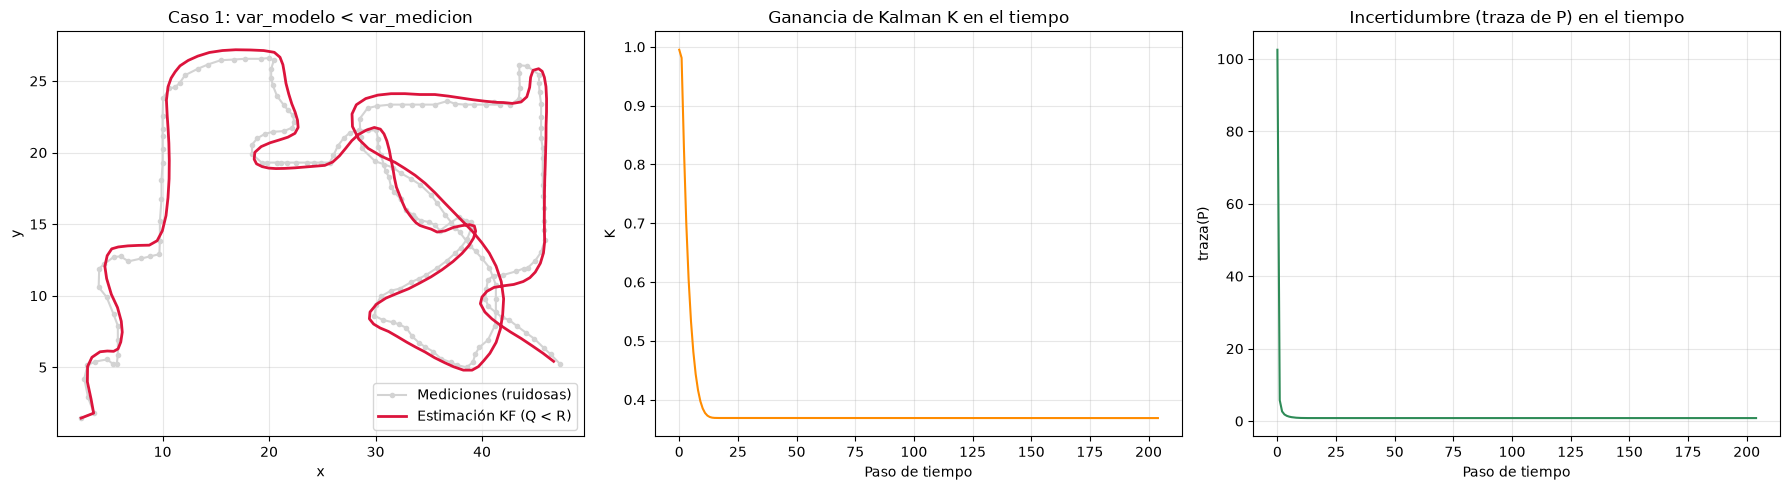

In [20]:
# Gráficas del Caso 1: trayectoria + evolución de ganancia e incertidumbre
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

#  Trayectoria medida vs estimada por el KF
ax[0].plot(mediciones[:, 0], mediciones[:, 1], 'o-', color='lightgray',
           markersize=3, label='Mediciones (ruidosas)')
ax[0].plot(pos_kf_1[:, 0], pos_kf_1[:, 1], '-', color='crimson', lw=2,
           label='Estimación KF (Q < R)')
ax[0].set_title('Caso 1: var_modelo < var_medicion')
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].legend(); ax[0].grid(alpha=0.3)

#  Evolución de la ganancia de Kalman
ax[1].plot(ganancias_1, color='darkorange')
ax[1].set_title('Ganancia de Kalman K en el tiempo')
ax[1].set_xlabel('Paso de tiempo'); ax[1].set_ylabel('K'); ax[1].grid(alpha=0.3)

#  Evolución de la incertidumbre (traza de P)
ax[2].plot(trazas_1, color='seagreen')
ax[2].set_title('Incertidumbre (traza de P) en el tiempo')
ax[2].set_xlabel('Paso de tiempo'); ax[2].set_ylabel('traza(P)'); ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Análisis del Caso 1 (Q < R)

- **Ganancia K pequeña (~0.37 al final):** el filtro le da más peso al modelo que a las
  mediciones. Por eso la trayectoria estimada (roja) es una versión suavizada de la medida
  (gris): se elimina buena parte del ruido del sensor.
- **La incertidumbre (traza de P) decrece** desde ~102 hasta ~0.8 y se estabiliza: cada medición
  aporta información nueva, pero como el sensor es ruidoso, la reducción de incertidumbre es moderada.
- El **RMSE entre la estimación KF y las mediciones (0.69)** es del orden del ruido del sensor
  (√var_medicion = 1.0), lo cual confirma que el KF no sigue ciegamente las mediciones.

## 5. Caso 2 — varianza del modelo **mayor** que la varianza de medición

Ahora invertimos la confianza:

- `var_medicion = 0.01` → sensor muy preciso.
- `var_modelo = 1.0` → modelo poco fiable (el movimiento real puede alejarse mucho del modelo ideal).

Como **Q > R**, se espera una ganancia de Kalman **cercana a 1**: el filtro **confía
casi totalmente en las mediciones** y prácticamente ignora el modelo.

In [ ]:
# Caso 2: var_modelo (1.0) > var_medicion (0.01)
# ---------------------------------------------------------------
var_modelo_2, var_medicion_2 = 1.0, 0.01

estados_2, ganancias_2, trazas_2 = filtro_kalman_2d(mediciones, var_modelo_2, var_medicion_2)
pos_kf_2 = estados_2[:, :2]

print('Caso 2 -> var_modelo =', var_modelo_2, '| var_medicion =', var_medicion_2)
print('RMSE entre KF y mediciones:', round(rmse(pos_kf_2, mediciones), 4))
print('Ganancia K al inicio y al final:', round(ganancias_2[0], 3), '->', round(ganancias_2[-1], 3))
print('Traza de P al inicio y al final:', round(trazas_2[0], 2), '->', round(trazas_2[-1], 2))

Caso 2 -> var_modelo = 1.0 | var_medicion = 0.01
RMSE entre KF y mediciones: 0.0014
Ganancia K al inicio y al final: 1.0 -> 0.996
Traza de P al inicio y al final: 102.52 -> 3.27


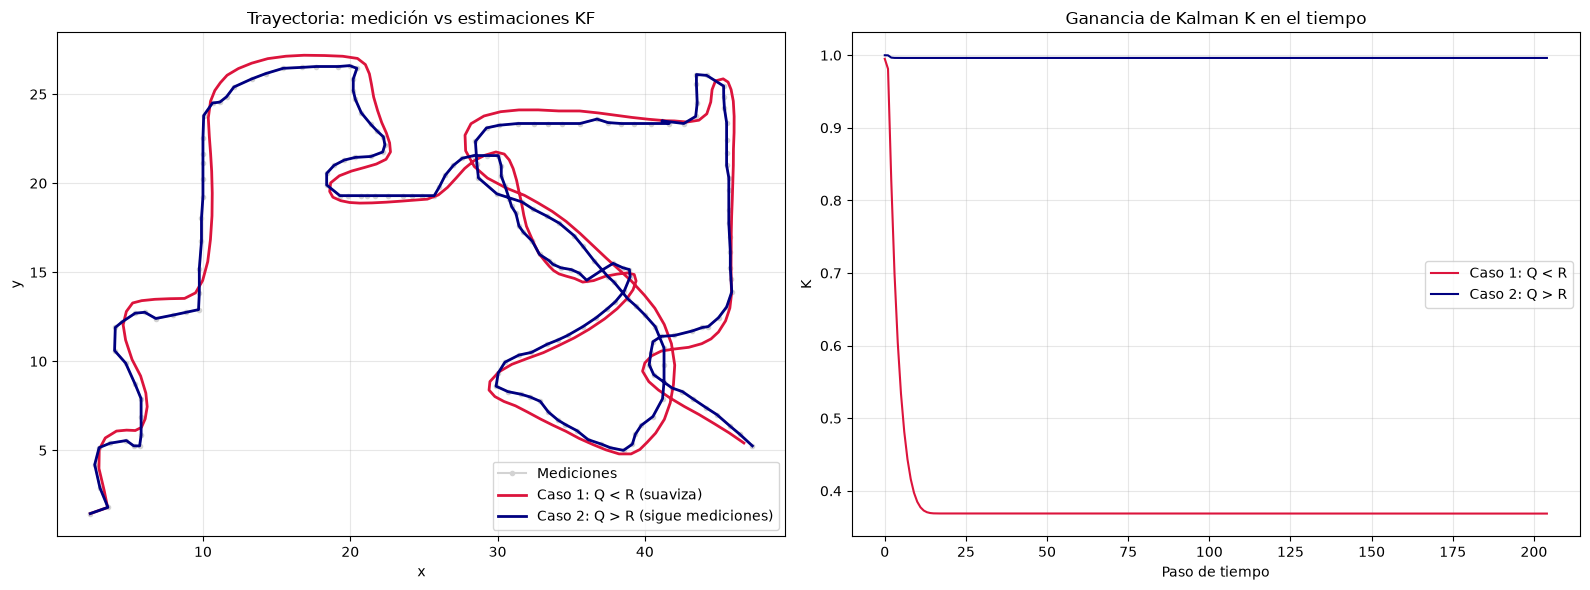

In [21]:
# Comparación visual de ambos casos
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# (a) Trayectorias estimadas en los dos casos
ax[0].plot(mediciones[:, 0], mediciones[:, 1], 'o-', color='lightgray',
           markersize=3, label='Mediciones')
ax[0].plot(pos_kf_1[:, 0], pos_kf_1[:, 1], '-', color='crimson', lw=2,
           label='Caso 1: Q < R (suaviza)')
ax[0].plot(pos_kf_2[:, 0], pos_kf_2[:, 1], '-', color='navy', lw=2,
           label='Caso 2: Q > R (sigue mediciones)')
ax[0].set_title('Trayectoria: medición vs estimaciones KF')
ax[0].set_xlabel('x'); ax[0].set_ylabel('y'); ax[0].legend(); ax[0].grid(alpha=0.3)

# (b) Ganancia de Kalman en ambos casos
ax[1].plot(ganancias_1, color='crimson', label='Caso 1: Q < R')
ax[1].plot(ganancias_2, color='navy', label='Caso 2: Q > R')
ax[1].set_title('Ganancia de Kalman K en el tiempo')
ax[1].set_xlabel('Paso de tiempo'); ax[1].set_ylabel('K')
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:
# Tabla resumen de ambos casos
resumen = pd.DataFrame({
    'Caso': ['1: Q < R (modelo fiable)', '2: Q > R (sensor fiable)'],
    'var_modelo (Q)': [var_modelo_1, var_modelo_2],
    'var_medicion (R)': [var_medicion_1, var_medicion_2],
    'K final': [round(ganancias_1[-1], 3), round(ganancias_2[-1], 3)],
    'Traza(P) final': [round(trazas_1[-1], 2), round(trazas_2[-1], 2)],
    'RMSE KF vs mediciones': [round(rmse(pos_kf_1, mediciones), 3),
                              round(rmse(pos_kf_2, mediciones), 4)],
})
print(resumen.to_string(index=False))

                    Caso  var_modelo (Q)  var_medicion (R)  K final  Traza(P) final  RMSE KF vs mediciones
1: Q < R (modelo fiable)            0.01              1.00    0.369            0.83                 0.6870
2: Q > R (sensor fiable)            1.00              0.01    0.996            3.27                 0.0014


### Análisis del Caso 2 (Q > R)

- **Ganancia K ≈ 1 (0.996 al final):** la medición es mucho más confiable que el modelo, así que
  la corrección `x̂ = x̂⁻ + K·(z − H·x̂⁻)` incorpora casi **todo** el residuo de la medición.
  La estimación KF (azul) prácticamente **coincide con las mediciones**.
- El **RMSE entre KF y mediciones es casi 0** (0.001), confirmando que el filtro las sigue casi exactamente.
- La **incertidumbre final es mayor** que en el Caso 1 (3.27 vs 0.83): como el modelo no es
  confiable, la predicción entre mediciones acumula mucho ruido y la covarianza no puede reducirse tanto.

## 6. ¿Converge la estimación del KF?

**Sí, en ambos casos el filtro converge**, y se demuestra con dos evidencias:

1. **Convergencia de la covarianza (traza de P):** tras unas pocas iteraciones la traza deja de
   decreer de forma pronunciada y **se estabiliza en un valor fijo** (estado estacionario).
   Esto significa que el filtro ya no gana más información: alcanzó su nivel de precisión máximo.
2. **Convergencia de la ganancia K:** K deja de variar y se mantiene prácticamente constante,
   lo cual es la condición típica de convergencia de un filtro de Kalman (ganancia estacionaria).

**Interpretación:** la convergencia no depende tanto de los valores absolutos de Q y R como de su
**razón**. En el Caso 1 (Q ≪ R) converge a una solución *suavizada* (estima una trayectoria limpia);
en el Caso 2 (Q ≫ R) converge a la *medición misma*. En ninguno de los dos diverge, porque el sistema
es estable (los autovalores de F están en el círculo unitario) y las matrices Q, R son definidas positivas.

## Conclusiones del Ejercicio 1

1. Se implementó el filtro de Kalman **completo y desde cero** (predicción, ganancia y
   actualización) sobre un modelo de velocidad constante en 2D.
2. La **estimación inicial** toma la primera medición como posición, velocidad 0 e incertidumbre alta (100·I).
3. Con **Q < R** (Caso 1) el filtro **suaviza** las mediciones: la ganancia es pequeña y la
   trayectoria estimada es limpia. Este es el uso típico: eliminar ruido del sensor.
4. Con **Q > R** (Caso 2) el filtro **sigue las mediciones** casi exactamente (K ≈ 1); útil solo
   cuando el sensor es muy preciso.
5. **La estimación converge en ambos casos**, evidenciado por la estabilización de la ganancia de
   Kalman y de la traza de la covarianza, que llegan a un **estado estacionario** y dejan de cambiar.
6. La clave del comportamiento del KF es la **razón Q/R**: ella determina cuánto se confía en el
   modelo frente a las mediciones.